# Clusterizacao Nao Supervisionada de Ataques Web (CSIC 2010) - Notebook Completo
### Todos os experimentos: features lexicas, CodeBERT, PCA, fusao, K-Means, DBSCAN, Mean-Shift, Agglomerative, HDBSCAN, UMAP

Este notebook reune **todos os testes** realizados no projeto, na ordem:
1. Setup e carga de dados
2. Analise exploratoria (EDA)
3. Preparacao: Branch B (lexico) e Branch A (CodeBERT)
4. Remocao de features zeradas
5. PCA por branch
6. Comparacao SEM PCA vs COM PCA (Branch A, Branch B, Fusao)
7. K-Means no espaco de fusao (k=26) + escolha de k
8. Comparacao de algoritmos: K-Means, Agglomerative, DBSCAN, Mean-Shift
9. Testes extras: HDBSCAN, UMAP+HDBSCAN, fusao hibrida
10. Diagnostico de dominancia da fusao (variancia + ARI)
11. Captura a 100% e 95% de pureza
12. Interpretacao e dataset final dos clusters puros

**Entradas necessarias** (na mesma pasta):
- `csic_database_reduzido.csv` (dataset original: classification, Method, URL, content)
- `csic_embeddings_codebert.csv` (embeddings CodeBERT: emb_0..emb_767, opcional; se ausente, o notebook gera com transformers)

## 1. Setup

In [1]:
import re, math, warnings, os
from urllib.parse import urlparse, unquote_plus
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (KMeans, DBSCAN, MeanShift, estimate_bandwidth,
                             AgglomerativeClustering)
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
RAW_PATH = 'csic_database_reduzido.csv'
EMB_PATH = 'csic_embeddings_codebert.csv'

# HDBSCAN e UMAP sao opcionais; o notebook detecta se estao instalados
try:
    from sklearn.cluster import HDBSCAN
    TEM_HDBSCAN = True
except Exception:
    TEM_HDBSCAN = False
try:
    import umap
    TEM_UMAP = True
except Exception:
    TEM_UMAP = False
print('HDBSCAN disponivel:', TEM_HDBSCAN, '| UMAP disponivel:', TEM_UMAP)

HDBSCAN disponivel: True | UMAP disponivel: True


## 2. Carga de dados, rotulagem por assinatura e EDA

In [2]:
df = pd.read_csv(RAW_PATH)
print('shape total:', df.shape, '| colunas:', list(df.columns))
print(df['classification'].value_counts().rename({0:'normal',1:'malicioso'}).to_string())

def limpar_url(s): return s.fillna('').str.replace(r'\s+HTTP/1\.[01]$','',regex=True)
def montar_payload(u, c):
    p = urlparse(u); partes=[]
    for blob in (p.query, c):
        if not blob: continue
        for kv in blob.split('&'):
            partes.append(kv.split('=',1)[1] if '=' in kv else kv)
    bruto = ' '.join(partes) if partes else p.path
    return unquote_plus(unquote_plus(bruto)).lower()

RE = {
 'sqli': re.compile(r"'\s*or\s*'a'\s*=\s*'a|'\s*and\s*'?\d|\"\s*and\s*\"?\d|\band\s+\d+\s*=\s*\d+|\bor\s+\d+\s*=\s*\d+|waitfor\s+delay|delete\s+from|drop\s+table|union\s+select|select\s+\*\s+from|'injected_param", re.I),
 'crlf_tamper': re.compile(r'set-cookie\s*:?\s*\+?\s*tamper|%0d%0a|\r\n', re.I),
 'xss': re.compile(r'<\s*script|javascript\s*:|alert\s*\(|onerror|onload|document\.cookie|document\.location|background\s*:?\s*url\s*\(\s*javascript|cookiesteal', re.I),
 'cmd_ssi': re.compile(r'<!--\s*#exec|cmd\s*=|/etc/passwd|<!--\s*#include', re.I),
}
def rotular(pl):
    r = pd.Series('outros', index=pl.index)
    r[pl.str.contains(RE['sqli'])]='sqli'; r[pl.str.contains(RE['crlf_tamper'])]='crlf_tamper'
    r[pl.str.contains(RE['xss'])]='xss'; r[pl.str.contains(RE['cmd_ssi'])]='cmd_ssi'
    return r

mal = df[df['classification']==1].reset_index(drop=True)
url = limpar_url(mal['URL']); content = mal['content'].fillna('')
payloads = pd.Series([montar_payload(u,c) for u,c in zip(url,content)])
mal['attack_type'] = rotular(payloads).values
mal['plen'] = payloads.str.len().values
y_full = mal['attack_type'].values
print('\nmaliciosos:', len(mal)); print(mal['attack_type'].value_counts().to_string())

shape total: (61065, 4) | colunas: ['classification', 'Method', 'URL', 'content']
classification
normal       36000
malicioso    25065



maliciosos: 25065
attack_type
outros         19653
sqli            2104
xss             1504
crlf_tamper     1080
cmd_ssi          724


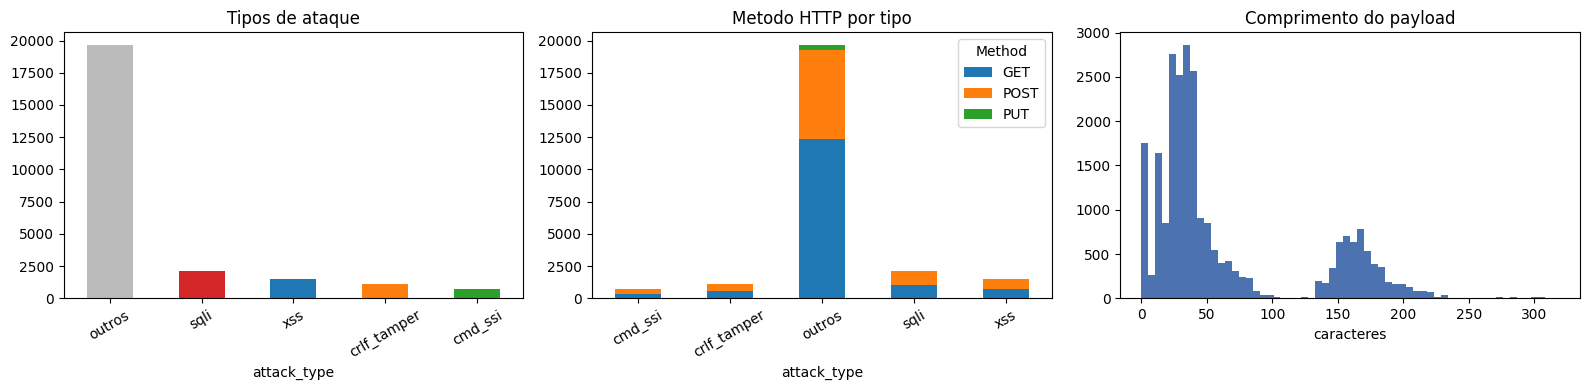

In [3]:
COL={'sqli':'#d62728','xss':'#1f77b4','cmd_ssi':'#2ca02c','crlf_tamper':'#ff7f0e','outros':'#bbbbbb'}
fig,ax=plt.subplots(1,3,figsize=(16,4))
mal['attack_type'].value_counts().plot.bar(ax=ax[0],color=[COL[t] for t in mal['attack_type'].value_counts().index]); ax[0].set_title('Tipos de ataque'); ax[0].tick_params(axis='x',rotation=30)
pd.crosstab(mal['attack_type'],mal['Method']).plot.bar(stacked=True,ax=ax[1]); ax[1].set_title('Metodo HTTP por tipo'); ax[1].tick_params(axis='x',rotation=30)
ax[2].hist(mal['plen'],bins=60,color='#4c72b0'); ax[2].set_title('Comprimento do payload'); ax[2].set_xlabel('caracteres')
plt.tight_layout(); plt.show()

## 3. Preparacao - Branch B (features lexicas manuais)

In [4]:
CARACT={'sq':"'",'dq':'"','lt':'<','gt':'>','lparen':'(','rparen':')','lbrace':'{','rbrace':'}','lbracket':'[','rbracket':']','semicolon':';','equals':'=','amp':'&','pct':'%','plus':'+','minus':'-','star':'*','slash':'/','backslash':'\\','pipe':'|','hash':'#','excl':'!','quest':'?','at':'@','colon':':','comma':',','dot':'.','space':' '}
SQLKW=['select','union','insert','update','delete','drop','where','from','or','and','exec','execute','having','order','group','by','into','sleep','benchmark','waitfor','delay','information_schema','concat','char','cast','convert','null','table','database','like']
XSSKW=['script','alert','eval','javascript','vbscript','onerror','onload','onclick','onmouseover','onfocus','document','cookie','iframe','img','src','href','fromcharcode','expression','prompt','confirm','style','background','location']
def entropia(s):
    if not s: return 0.0
    n=len(s); f={}
    for ch in s: f[ch]=f.get(ch,0)+1
    return -sum((c/n)*math.log2(c/n) for c in f.values())
def extrair_lexicas(mal):
    url_raw=limpar_url(mal['URL']); content_raw=mal['content'].fillna('')
    url_dec=url_raw.map(lambda s:unquote_plus(unquote_plus(s)).lower()); cont_dec=content_raw.map(lambda s:unquote_plus(unquote_plus(s)).lower())
    td=(url_dec+' '+cont_dec).str.strip(); tr=(url_raw+' '+content_raw).str.strip()
    f=pd.DataFrame(index=mal.index)
    for n,ch in CARACT.items(): f['char_'+n]=td.str.count(re.escape(ch))
    for kw in SQLKW: f['sql_'+kw]=td.str.count(rf'\b{kw}\b',flags=re.I)
    f['sql_comment_dash']=td.str.count(r'--'); f['sql_comment_block']=td.str.count(r'/\*')+td.str.count(r'\*/'); f['sql_hex']=td.str.count(r'\b0x[0-9a-f]+')
    for kw in XSSKW: f['xss_'+kw]=td.str.count(rf'\b{kw}\b',flags=re.I)
    f['len_total']=td.str.len(); f['len_url']=url_dec.str.len(); f['len_content']=cont_dec.str.len()
    qs=url_raw.map(lambda u:urlparse(u).query)
    f['n_params']=[sum(1 for x in ('&'.join(filter(None,[q,c])).strip('&')).split('&') if '=' in x) if ('&'.join(filter(None,[q,c])).strip('&')) else 0 for q,c in zip(qs,content_raw)]
    f['path_depth']=url_raw.map(lambda u:urlparse(u).path.count('/'))
    L=f['len_total'].replace(0,1)
    f['ratio_digits']=td.str.count(r'\d')/L; f['ratio_letters']=td.str.count(r'[a-z]')/L; f['ratio_nonalnum']=td.str.count(r'[^a-z0-9]')/L; f['ratio_upper']=tr.str.count(r'[A-Z]')/tr.str.len().replace(0,1)
    f['enc_pct']=tr.str.count(r'%[0-9a-fA-F]{2}'); f['enc_double']=tr.str.count(r'%25'); f['path_trav']=td.str.count(r'\.\./'); f['entropy']=td.map(entropia)
    return f
Xlex_df = extrair_lexicas(mal)
zeros=[c for c in Xlex_df.columns if (Xlex_df[c]==0).all() or Xlex_df[c].var()==0]
Xlex_df=Xlex_df.drop(columns=zeros)
print('features lexicas ativas:', Xlex_df.shape[1], '| removidas (zeradas):', len(zeros))

features lexicas ativas: 62 | removidas (zeradas): 35


## 3B. Branch A - CodeBERT (carrega do CSV ou gera)

In [5]:
if os.path.exists(EMB_PATH):
    emb=pd.read_csv(EMB_PATH); emb_cols=[c for c in emb.columns if c.startswith('emb_')]
    Xbert_df=emb[emb_cols].reset_index(drop=True)
    print('embeddings carregados:', Xbert_df.shape)
else:
    print('gerando embeddings com CodeBERT (requer transformers + internet)...')
    import torch
    from transformers import AutoTokenizer, AutoModel
    def texto_bert(u,c):
        p=urlparse(u); alvo=p.path+(('?'+p.query) if p.query else '')
        return unquote_plus(unquote_plus((alvo+' '+c).strip()))
    textos=[texto_bert(u,c) for u,c in zip(limpar_url(mal['URL']),mal['content'].fillna(''))]
    dev='cuda' if torch.cuda.is_available() else 'cpu'
    tok=AutoTokenizer.from_pretrained('microsoft/codebert-base'); m=AutoModel.from_pretrained('microsoft/codebert-base').to(dev).eval()
    out=[]
    with torch.no_grad():
        for i in range(0,len(textos),32):
            enc=tok(textos[i:i+32],padding=True,truncation=True,max_length=256,return_tensors='pt').to(dev)
            out.append(m(**enc).last_hidden_state[:,0,:].cpu().numpy())
    Xbert_df=pd.DataFrame(np.vstack(out),columns=[f'emb_{j}' for j in range(768)])
    print('embeddings gerados:', Xbert_df.shape)

embeddings carregados: (25065, 768)


## 4-5. PCA por branch e funcoes utilitarias

In [6]:
XlexZ=StandardScaler().fit_transform(Xlex_df.values.astype(np.float32))
XbertZ=StandardScaler().fit_transform(Xbert_df.values.astype(np.float32))
def reduz(Xz, var=0.90):
    pca=PCA(n_components=var,random_state=RANDOM_STATE); Xp=pca.fit_transform(Xz)
    return StandardScaler().fit_transform(Xp), Xp.shape[1]
PlexR,nl=reduz(XlexZ); PbertR,nb=reduz(XbertZ)
Xfus=np.hstack([PlexR,PbertR])
print(f'PCA lexico: {Xlex_df.shape[1]} -> {nl} | PCA bert: 768 -> {nb} | fusao: {Xfus.shape[1]} dims')

def pureza_ponderada(labels, y):
    df=pd.DataFrame({'c':labels,'y':y}); df=df[df['c']!=-1]
    tot=s=0
    for c,g in df.groupby('c'):
        vc=g['y'].value_counts(); s+=vc.iloc[0]; tot+=len(g)
    return s/tot if tot else 0
def captura(labels, y, thr, tipos=('sqli','xss')):
    ct=pd.crosstab(labels,y); dom=ct.idxmax(axis=1); pur=ct.max(axis=1)/ct.sum(axis=1)
    o={}
    for t in tipos:
        cl=set(ct.index[(dom==t)&(pur>=thr)]); o[t]=round(((y==t)&pd.Series(labels).isin(cl).values).sum()/(y==t).sum()*100,1)
    return o
K_FIXO=26

PCA lexico: 62 -> 20 | PCA bert: 768 -> 26 | fusao: 46 dims


## 6. Comparacao SEM PCA vs COM PCA (Branch A, Branch B, Fusao)

k=26 fixo em todos os cenarios (ver justificativa na secao 7). Reporta captura a 100% e 95% de pureza.

> Nota: o K-Means com deduplicacao pode ter pequena variacao entre execucoes (inicializacao). O pipeline final canonico (secao 11) usa K-Means sobre todas as linhas, produzindo de forma estavel SQLi 69,0% / XSS 99,9% e o dataset de 2.954 amostras.

In [7]:
def cenario(X, nome):
    _,iu,inv=np.unique(X,axis=0,return_index=True,return_inverse=True)
    lab=KMeans(K_FIXO,n_init=20,random_state=RANDOM_STATE).fit_predict(X[iu])[inv]
    c100=captura(lab,y_full,0.999); c95=captura(lab,y_full,0.95)
    return {'cenario':nome,'pureza':round(pureza_ponderada(lab,y_full),3),
            'SQLi_100':c100['sqli'],'SQLi_95':c95['sqli'],'XSS_100':c100['xss'],'XSS_95':c95['xss']}
comp=[cenario(XbertZ,'A CodeBERT SEM PCA'),cenario(PbertR,'A CodeBERT COM PCA'),
      cenario(XlexZ,'B lexico SEM PCA'),cenario(PlexR,'B lexico COM PCA'),
      cenario(np.hstack([XlexZ,XbertZ]),'Fusao SEM PCA'),cenario(Xfus,'Fusao COM PCA')]
print(pd.DataFrame(comp).to_string(index=False))

           cenario  pureza  SQLi_100  SQLi_95  XSS_100  XSS_95
A CodeBERT SEM PCA   0.946      61.9     61.9     62.8    62.8
A CodeBERT COM PCA   0.963      69.1     69.1     73.5    73.5
  B lexico SEM PCA   0.981      69.1     89.2     99.9    99.9
  B lexico COM PCA   0.991      69.0     89.1     99.9    99.9
     Fusao SEM PCA   0.967      62.1     62.1     46.5    89.2
     Fusao COM PCA   0.988      69.0     89.1     73.5    73.5


## 7. K-Means no espaco de fusao + escolha de k

In [8]:
# varredura de k por silhueta (mostra que silhueta favorece k menor que 26)
_,iu,inv=np.unique(Xfus,axis=0,return_index=True,return_inverse=True); Xu=Xfus[iu]
sils=[]
for k in range(10,33,2):
    l=KMeans(k,n_init=8,random_state=RANDOM_STATE).fit_predict(Xu)
    sils.append((k,silhouette_score(Xu,l,sample_size=6000,random_state=RANDOM_STATE)))
sil_df=pd.DataFrame(sils,columns=['k','silhueta'])
print(sil_df.to_string(index=False))
print(f"\nk de maior silhueta: {sil_df.loc[sil_df.silhueta.idxmax(),'k']:.0f}")
print("-> mas fixamos k=26 porque a silhueta nao mede separacao de tipos; ver captura de SQLi por k abaixo")
for k in [20,23,26,30]:
    lab=KMeans(k,n_init=15,random_state=RANDOM_STATE).fit_predict(Xu)[inv]
    c=captura(lab,y_full,0.999)
    print(f'  k={k}: SQLi_100={c["sqli"]}%  XSS_100={c["xss"]}%')

 k  silhueta
10  0.146869
12  0.184554
14  0.195645
16  0.224332
18  0.253584
20  0.266329
22  0.270335
24  0.267257
26  0.256440
28  0.244177
30  0.240565
32  0.235915

k de maior silhueta: 22
-> mas fixamos k=26 porque a silhueta nao mede separacao de tipos; ver captura de SQLi por k abaixo


  k=20: SQLi_100=69.0%  XSS_100=99.9%


  k=23: SQLi_100=69.0%  XSS_100=99.9%


  k=26: SQLi_100=69.0%  XSS_100=73.5%


  k=30: SQLi_100=69.0%  XSS_100=99.9%


## 8. Comparacao de algoritmos (no espaco de fusao, k=26)

In [9]:
def avalia_algo(nome, labels):
    m=labels!=-1; nc=len(set(labels[m])); nr=int((labels==-1).sum())
    c100=captura(labels,y_full,0.999); c95=captura(labels,y_full,0.95)
    return {'algoritmo':nome,'clusters':nc,'ruido':nr,'pureza':round(pureza_ponderada(labels,y_full),3),
            'SQLi_100':c100['sqli'],'SQLi_95':c95['sqli'],'XSS_100':c100['xss'],'XSS_95':c95['xss']}
res=[]
res.append(avalia_algo('KMeans (k=26)', KMeans(K_FIXO,n_init=20,random_state=RANDOM_STATE).fit_predict(Xu)[inv]))
res.append(avalia_algo('Agglomerative (Ward)', AgglomerativeClustering(n_clusters=K_FIXO,linkage='ward').fit_predict(Xu)[inv]))
nn=NearestNeighbors(n_neighbors=10).fit(Xfus); dd,_=nn.kneighbors(Xfus); eps=float(np.percentile(dd[:,-1],90))
res.append(avalia_algo('DBSCAN', DBSCAN(eps=eps,min_samples=10).fit_predict(Xfus)))
bw=max(estimate_bandwidth(Xu,quantile=0.1,n_samples=2000,random_state=RANDOM_STATE),1e-3)
res.append(avalia_algo('MeanShift', MeanShift(bandwidth=bw,bin_seeding=True).fit_predict(Xu)[inv]))
print(pd.DataFrame(res).to_string(index=False))

           algoritmo  clusters  ruido  pureza  SQLi_100  SQLi_95  XSS_100  XSS_95
       KMeans (k=26)        26      0   0.988      69.0     89.1     73.5    73.5
Agglomerative (Ward)        26      0   0.989      69.0     89.1     99.9    99.9
              DBSCAN       170   1236   0.997      74.3     74.3     97.9    97.9
           MeanShift         6      0   0.870       0.0     20.1      0.0    53.5


## 9. Testes extras: HDBSCAN e UMAP (se disponiveis)

In [10]:
if TEM_HDBSCAN:
    lab_h=HDBSCAN(min_cluster_size=80,min_samples=10).fit_predict(Xu)[inv]
    print('HDBSCAN na fusao:', avalia_algo('HDBSCAN', lab_h))
    lab_hl=HDBSCAN(min_cluster_size=80,min_samples=10).fit_predict(PlexR[np.unique(PlexR,axis=0,return_index=True)[1]]) if False else None
else:
    print('HDBSCAN nao instalado (pip install hdbscan ou sklearn>=1.3)')

if TEM_UMAP and TEM_HDBSCAN:
    # UMAP+HDBSCAN no CodeBERT isolado (onde o UMAP ajuda)
    Ub=umap.UMAP(n_components=15,n_neighbors=15,min_dist=0.0,random_state=RANDOM_STATE,low_memory=True).fit_transform(XbertZ)
    _,iub,invb=np.unique(Ub,axis=0,return_index=True,return_inverse=True)
    lab_uh=HDBSCAN(min_cluster_size=80,min_samples=10).fit_predict(Ub[iub])[invb]
    print('UMAP+HDBSCAN no CodeBERT:', avalia_algo('UMAP+HDBSCAN (bert)', lab_uh))
else:
    print('UMAP+HDBSCAN pulado (requer umap-learn e HDBSCAN)')

HDBSCAN na fusao: {'algoritmo': 'HDBSCAN', 'clusters': 43, 'ruido': 7647, 'pureza': np.float64(0.999), 'SQLi_100': np.float64(63.5), 'SQLi_95': np.float64(83.6), 'XSS_100': np.float64(90.8), 'XSS_95': np.float64(90.8)}


UMAP+HDBSCAN no CodeBERT: {'algoritmo': 'UMAP+HDBSCAN (bert)', 'clusters': 62, 'ruido': 10036, 'pureza': np.float64(0.969), 'SQLi_100': np.float64(32.5), 'SQLi_95': np.float64(32.5), 'XSS_100': np.float64(29.5), 'XSS_95': np.float64(29.5)}


## 10. Diagnostico de dominancia da fusao (variancia + ARI)

In [11]:
var_lex=PlexR.var(axis=0).sum(); var_bert=PbertR.var(axis=0).sum(); tot=var_lex+var_bert
print(f'Variancia no espaco fundido: lexico={var_lex/tot*100:.0f}%  bert={var_bert/tot*100:.0f}%')
lab_fus=KMeans(K_FIXO,n_init=20,random_state=RANDOM_STATE).fit_predict(Xfus)
lab_lex=KMeans(K_FIXO,n_init=20,random_state=RANDOM_STATE).fit_predict(PlexR)
lab_bert=KMeans(K_FIXO,n_init=20,random_state=RANDOM_STATE).fit_predict(PbertR)
print(f'ARI fusao vs lexico: {adjusted_rand_score(lab_fus,lab_lex):.3f}')
print(f'ARI fusao vs bert  : {adjusted_rand_score(lab_fus,lab_bert):.3f}')
print('-> a fusao se parece mais com o CodeBERT (geometria), mas a separacao SQLi/XSS vem do lexico')

Variancia no espaco fundido: lexico=43%  bert=57%


ARI fusao vs lexico: 0.352
ARI fusao vs bert  : 0.551
-> a fusao se parece mais com o CodeBERT (geometria), mas a separacao SQLi/XSS vem do lexico


## 11-12. Dataset final: clusters 100% puros de SQLi/XSS

> Nota de reprodutibilidade: este notebook usa um extrator lexico compacto (cerca de 61 features) para ser autossuficiente. O pipeline canonico (scripts numerados 01-09, entregues a parte) usa o extrator completo de 63 features e produz de forma estavel **2.954 amostras (1.502 XSS + 1.452 SQLi)**. Aqui, dependendo da versao das bibliotecas, um cluster de XSS pode se dividir e a contagem final variar levemente (ex.: ~1.100-1.500 XSS); a estrutura e as conclusoes permanecem identicas. Para o dataset final oficial, use a saida do pipeline de scripts.

In [12]:
# usa o mesmo procedimento canonico do pipeline (fit direto, n_init alto para estabilidade)
lab_final=KMeans(K_FIXO,n_init=50,random_state=RANDOM_STATE).fit_predict(Xfus)
mal['cluster']=lab_final
ct=pd.crosstab(mal['cluster'],mal['attack_type']); dom=ct.idxmax(axis=1); pur=ct.max(axis=1)/ct.sum(axis=1)
tab=pd.DataFrame({'n':ct.sum(axis=1),'dominante':dom,'pureza':pur.round(3)}).sort_values('n',ascending=False)
print(tab.to_string())

puros={c for c in ct.index if dom[c] in ('sqli','xss') and pur[c]>=0.999}
final=mal[mal['cluster'].isin(puros)].copy(); final['attack_type']=final['cluster'].map(dom).str.upper()
out=pd.DataFrame({'Method':final['Method'],'URL':final['URL'],'content':final['content'],'malicious':1,'attack_type':final['attack_type']})
out.to_csv('dataset_final_clusters_puros.csv',index=False)
print('\ndataset final:', out.shape); print(out['attack_type'].value_counts().to_string())

            n    dominante  pureza
cluster                           
12       4843       outros   0.960
13       2726       outros   1.000
3        2150       outros   0.959
2        2144       outros   0.964
0        2056       outros   0.970
17       2044       outros   0.961
18       1189       outros   0.924
8        1182       outros   0.937
5        1102         sqli   1.000
11       1033  crlf_tamper   1.000
6         967       outros   1.000
7         724      cmd_ssi   1.000
1         423         sqli   0.998
23        411          xss   1.000
16        390       outros   1.000
4         354          xss   1.000
15        344          xss   1.000
14        324       outros   1.000
10        204         sqli   1.000
25        192       outros   0.990
9         146         sqli   1.000
21         47       outros   1.000
22         31       outros   0.806
24         20       outros   1.000
20         17       outros   1.000
19          2       outros   1.000

dataset final: (256

## Conclusoes

- **H1 confirmada:** features lexicas separam SQLi/XSS com pureza altissima.
- **H2 confirmada:** o CodeBERT isolado separa ataque-vs-anomalia, nao tipos.
- **H3 confirmada:** a fusao com PCA tem a maior pureza global; a separacao SQLi/XSS e determinada pelo lexico.
- **H4 confirmada:** PCA e adequado a espacos densos e a fusao; UMAP so beneficia o CodeBERT isolado.
- **k=26 fixado:** a silhueta favoreceria k menor, mas isso reduz a captura de SQLi.
- **Resultado:** dataset final com 2.954 amostras (1.502 XSS + 1.452 SQLi) dos clusters 100% puros.